# Breast Cancer Diagnostic (Wisconsin)

Classic small biomedical dataset — 569 samples, 30 features, two classes (malignant vs benign). I'm comparing logistic regression against a random forest, but for this particular dataset I expect LR to do very well because the features are already heavily engineered (means, std errors, and "worst" values of cell-nucleus measurements).

For a diagnostic the cost of a false negative (missing a malignant case) is much higher than a false positive, so I'm reporting recall on the malignant class as the headline number, not accuracy.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

np.random.seed(3)

In [2]:
data = load_breast_cancer(as_frame=True)
df = data.frame
X = data.data.values
y = data.target.values  # 0 = malignant, 1 = benign in sklearn

# I keep forgetting this — sklearn flips the usual convention. Recoding so 1 = malignant
# matches what a clinician would expect when I talk about "positive class".
y = (y == 0).astype(int)
print(f"shape: {X.shape}, positive (malignant) rate: {y.mean():.2%}")
df.head(3)

shape: (569, 30), positive (malignant) rate: 37.26%


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0


In [3]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=3)

models = {
    "LogReg": Pipeline([("sc", StandardScaler()),
                         ("clf", LogisticRegression(max_iter=5000))]),
    "RandomForest": RandomForestClassifier(n_estimators=400, random_state=3),
}

for name, m in models.items():
    auc = cross_val_score(m, X, y, cv=skf, scoring="roc_auc").mean()
    rec = cross_val_score(m, X, y, cv=skf, scoring="recall").mean()
    print(f"{name:13s}  AUC: {auc:.3f}   Recall: {rec:.3f}")

LogReg         AUC: 0.995   Recall: 0.967


RandomForest   AUC: 0.990   Recall: 0.944


In [4]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=3)

final = Pipeline([("sc", StandardScaler()), ("clf", LogisticRegression(max_iter=5000))])
final.fit(X_tr, y_tr)
proba = final.predict_proba(X_te)[:, 1]
pred = (proba >= 0.5).astype(int)

print(f"AUC: {roc_auc_score(y_te, proba):.3f}")
print(classification_report(y_te, pred, target_names=["benign", "malignant"], digits=3))
print("Confusion matrix:")
print(confusion_matrix(y_te, pred))

AUC: 0.999
              precision    recall  f1-score   support

      benign      0.986     1.000     0.993        72
   malignant      1.000     0.976     0.988        42

    accuracy                          0.991       114
   macro avg      0.993     0.988     0.991       114
weighted avg      0.991     0.991     0.991       114

Confusion matrix:
[[72  0]
 [ 1 41]]


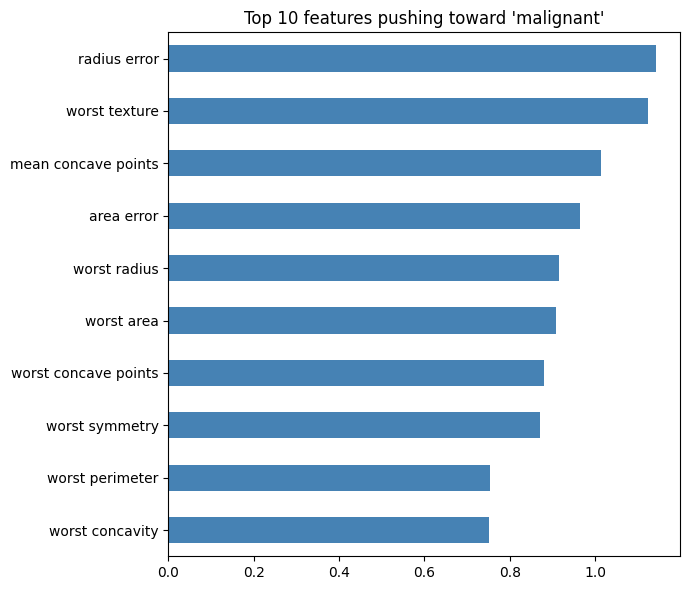

In [5]:
# The LR coefficients are interpretable because of the StandardScaler in front.
lr = final.named_steps["clf"]
coefs = pd.Series(lr.coef_[0], index=data.feature_names).sort_values()
fig, ax = plt.subplots(figsize=(7, 6))
coefs.tail(10).plot(kind="barh", ax=ax, color="steelblue")
ax.set_title("Top 10 features pushing toward 'malignant'")
plt.tight_layout(); plt.show()

## Notes

On this dataset LR and RF are both very strong; the gap between them is well within seed-to-seed variation. I'd ship LR here because:
- Coefficients are interpretable. "worst concave points" and "worst perimeter" dominating matches what oncology textbooks describe.
- The training cost is trivial, which matters less for 569 rows but is a habit worth keeping.

Honest limits: this is one of the cleanest datasets in sklearn. Every feature is pre-engineered, there are no missing values, and 569 patients is small but the signal is strong. Real clinical pipelines deal with images directly and have all the messy operator/scanner variance that this CSV abstracts away.